# Mini-Project 1: Direct HTTP weather forecasts
Author: MAGALA MUHUSINU , REG_NO S26M19/046, ACCESS_NO B40820. The saved outputs come from a live run (LIVE = True) against the real APIs; the offline fixtures used when LIVE = False are synthetic, not real forecasts. All manual settings are in one configuration cell. No input() prompts.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as _display, HTML, Markdown

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if not (ROOT / "src").exists():
    raise RuntimeError("Launch from repository root or notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
rng = np.random.default_rng(2026)


def load_sample(name):
    return json.loads((ROOT / "data" / "samples" / name).read_text(encoding="utf-8"))


def display(obj):
    if isinstance(obj, pd.DataFrame):
        _display(HTML(obj.to_html(index=False)))
    elif isinstance(obj, pd.io.formats.style.Styler):
        _display(HTML(obj.to_html()))
    else:
        _display(obj)

In [2]:
import os

LOCATION = "Kampala"
CONTACT_EMAIL = os.getenv("UNIVERSITY_EMAIL", "")
CANDIDATE_INDEX = 0
DAYS = 7
LIVE = True

In [3]:
from src.weather import *

print("LIVE MODE" if LIVE else "OFFLINE DEMONSTRATION — synthetic weather values")

LIVE MODE


## Part A: HTTP fundamentals
urllib uses urlencode, Request, urlopen and json decoding. requests uses params=, timeout and raise_for_status. urllib instead raises HTTPError and has no raise_for_status method.

In [4]:
if LIVE:
    raw_u, meta_u = urllib_geocode(LOCATION, CONTACT_EMAIL)
    raw_r, meta_r = request_json(
        GEOCODING,
        {"name": LOCATION, "count": 10, "language": "en", "format": "json"},
        CONTACT_EMAIL,
    )
    display(
        pd.DataFrame([meta_u, meta_r], index=["urllib", "requests"]).reset_index(
            names="Client"
        )
    )
    print("Candidates:", len(parse_candidates(raw_u)), len(parse_candidates(raw_r)))
else:
    print(
        "No actual HTTP measurements in offline mode; status/header/timing are not invented."
    )

Client,status,content_type,seconds,attempts
urllib,200,application/json; charset=utf-8,1.693163,1
requests,200,application/json; charset=utf-8,0.810956,1


Candidates: 10 10


### Client comparison
| Aspect | urllib | requests |
|---|---|---|
| Length | Explicit URL and body decoding | Short params= and .json() |
| Errors | HTTPError/URLError | raise_for_status and connection/timeout types |
| Headers | Request headers | get headers |
| Encoding | urlencode and explicit decoding | Encoded params and JSON decoder |
| Dependency | Standard library | Third-party |

Timeouts bound each attempt, not all backoff/retries combined.

## Part B:  candidate selection and forecast

In [5]:
candidates = (
    geocode(LOCATION, CONTACT_EMAIL)
    if LIVE
    else parse_candidates(load_sample("geocoding_kampala.json"))
)
display(pd.DataFrame(candidates))
selected = choose_candidate(candidates, CANDIDATE_INDEX)
print("Selected:", selected["name"])
ambiguous = parse_candidates(load_sample("geocoding_ambiguous.json"))
print("Ambiguity demonstration: inspect candidates and set your configured index.")
display(pd.DataFrame(ambiguous))
print("Explicit second-candidate example:", choose_candidate(ambiguous, 1))

id,name,latitude,longitude,elevation,feature_code,country_code,admin1_id,admin2_id,admin3_id,admin4_id,timezone,population,country_id,country,admin1,admin2,admin3,admin4
232422,Kampala,0.31628,32.58219,1223.0,PPLC,UG,234594,443339.0,8644170.0,8658346.0,Africa/Kampala,1680600.0,226074,Uganda,Central Region,Kampala District,Kampala Capital City,Central Division
12687984,Kampala,7.32344,-7.68519,560.0,PPL,CI,11153058,11153165.0,2284646.0,NaN,Africa/Abidjan,462.0,2287781,Ivory Coast,Montagnes,Tonkpi,Man,NaN
214583,Kampala,2.30086,30.59269,1647.0,PPL,CD,215709,12278165.0,NaN,NaN,Africa/Lubumbashi,NaN,203312,Democratic Republic of Congo,Ituri,Mahagi,NaN,NaN
214584,Kampala,-2.19509,27.74864,648.0,PPL,CD,205413,12278023.0,NaN,NaN,Africa/Lubumbashi,NaN,203312,Democratic Republic of Congo,South Kivu,Shabunda,NaN,NaN
914306,Kampala,-14.41129,31.60980,1053.0,PPL,ZM,917388,NaN,NaN,NaN,Africa/Lusaka,NaN,895949,Zambia,Eastern Province,NaN,NaN,NaN
1902624,Kampala,-5.01350,119.52490,3.0,PPL,ID,1626232,1636028.0,NaN,NaN,Asia/Makassar,NaN,1643084,Indonesia,South Sulawesi,Maros Regency,NaN,NaN
1967078,Kampala,-5.00310,119.78110,385.0,PPL,ID,1626232,1636028.0,NaN,NaN,Asia/Makassar,NaN,1643084,Indonesia,South Sulawesi,Maros Regency,NaN,NaN
6751563,Kampala,-5.15040,120.05880,403.0,PPL,ID,1626232,1626894.0,NaN,NaN,Asia/Makassar,NaN,1643084,Indonesia,South Sulawesi,Kabupaten Sinjai,NaN,NaN
6751564,Kampala,-5.15410,120.22300,107.0,PPL,ID,1626232,1626894.0,NaN,NaN,Asia/Makassar,NaN,1643084,Indonesia,South Sulawesi,Kabupaten Sinjai,NaN,NaN
6752917,Kampala,-5.47580,120.00530,306.0,PPL,ID,1626232,1650183.0,NaN,NaN,Asia/Makassar,NaN,1643084,Indonesia,South Sulawesi,Bantaeng Regency,NaN,NaN


Selected: Kampala
Ambiguity demonstration: inspect candidates and set your configured index.


name,latitude,longitude,admin1,country
Springfield,39.8,-89.6,Illinois,United States
Springfield,42.1,-72.6,Massachusetts,United States


Explicit second-candidate example: {'name': 'Springfield', 'latitude': 42.1, 'longitude': -72.6, 'admin1': 'Massachusetts', 'country': 'United States'}


Timezone: Africa/Kampala


,Date,Maximum temperature (°C),Minimum temperature (°C),Precipitation (mm),Maximum wind (km/h),Weather code,Description
0,2026-10-16 00:00:00,24.8,17.9,17.7,18.4,81,Moderate rain showers
1,2026-10-17 00:00:00,25.1,18.0,17.6,14.5,81,Moderate rain showers
2,2026-10-18 00:00:00,27.2,17.9,4.8,10.2,55,Dense drizzle
3,2026-10-19 00:00:00,26.9,18.2,2.7,8.8,80,Slight rain showers
4,2026-10-20 00:00:00,26.8,18.6,9.0,7.6,80,Slight rain showers
5,2026-10-21 00:00:00,27.4,18.2,5.4,6.0,55,Dense drizzle
6,2026-10-22 00:00:00,26.8,18.8,1.2,9.2,51,Light drizzle


7 days; minimum 17.9 °C; maximum 27.4 °C; precipitation 58.4 mm.


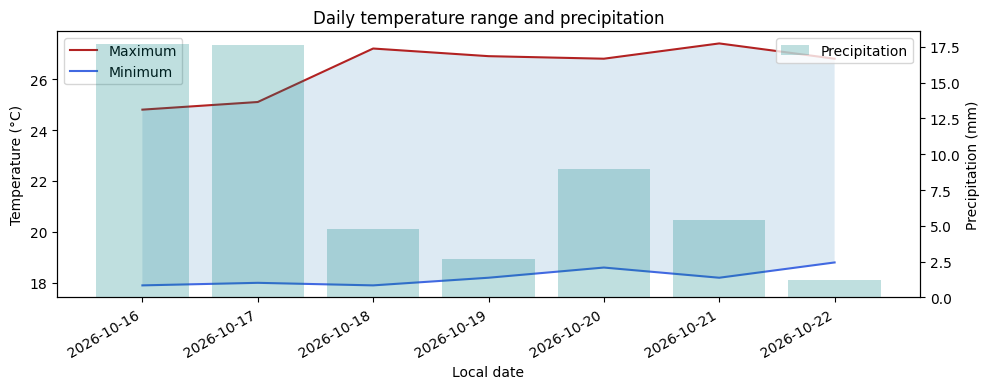

Sources: [Open-Meteo](https://open-meteo.com/), [GeoNames](https://www.geonames.org/), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Table/chart transform daily fields. Live response.

In [6]:
payload = (
    get_forecast(selected["latitude"], selected["longitude"], DAYS, CONTACT_EMAIL)
    if LIVE
    else load_sample("forecast_kampala.json")
)
frame = parse_forecast(payload)
print("Timezone:", payload["timezone"])
display(
    frame.style.format(
        {
            "Maximum temperature (°C)": "{:.1f}",
            "Minimum temperature (°C)": "{:.1f}",
            "Precipitation (mm)": "{:.1f}",
            "Maximum wind (km/h)": "{:.1f}",
        }
    )
)
print(forecast_summary(frame))
fig = plot_forecast(frame)
plt.show()
display(
    Markdown(
        "Sources: [Open-Meteo](https://open-meteo.com/), [GeoNames](https://www.geonames.org/), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Table/chart transform daily fields. "
        + (
            "Live response."
            if LIVE
            else "Synthetic demonstration, not provider-issued forecasts."
        )
    )
)

## Part C: second source and robustness

In [7]:
met_payload = (
    get_met_forecast(selected["latitude"], selected["longitude"], CONTACT_EMAIL)
    if LIVE
    else load_sample("met_kampala.json")
)
met = parse_met(met_payload)
met["Local date"] = (
    met["Time (UTC)"].dt.tz_convert(payload["timezone"]).dt.strftime("%Y-%m-%d")
)
daily = frame.copy()
daily["Local date"] = daily["Date"].dt.strftime("%Y-%m-%d")
comparison = met.merge(daily, on="Local date", how="inner")
comparison["Inside daily range"] = comparison["Temperature (°C)"].between(
    comparison["Minimum temperature (°C)"], comparison["Maximum temperature (°C)"]
)
display(
    comparison[["Time (UTC)", "Local date", "Temperature (°C)", "Inside daily range"]]
)
print(
    "Point samples are not daily extrema; this is consistency, not observed accuracy."
)
display(
    Markdown(
        "Second source: [MET Norway](https://www.met.no/), [licence](https://api.met.no/doc/License). "
        + ("Live transformed values." if LIVE else "Synthetic offline sample.")
    )
)

Time (UTC),Local date,Temperature (°C),Inside daily range
2026-10-16 09:00:00+00:00,2026-10-16,23.7,True
2026-10-16 10:00:00+00:00,2026-10-16,23.4,True
2026-10-16 11:00:00+00:00,2026-10-16,23.3,True
2026-10-16 12:00:00+00:00,2026-10-16,24.6,True
2026-10-16 13:00:00+00:00,2026-10-16,25.0,False
2026-10-16 14:00:00+00:00,2026-10-16,24.9,False
2026-10-16 15:00:00+00:00,2026-10-16,24.4,True
2026-10-16 16:00:00+00:00,2026-10-16,22.9,True
2026-10-16 17:00:00+00:00,2026-10-16,22.0,True
2026-10-16 18:00:00+00:00,2026-10-16,21.4,True


Point samples are not daily extrema; this is consistency, not observed accuracy.


Second source: [MET Norway](https://www.met.no/), [licence](https://api.met.no/doc/License). Live transformed values.

In [8]:
from unittest.mock import Mock, patch
import requests


def demonstrate(label, action):
    try:
        action()
    except WeatherError as exc:
        print(label, ":", exc)
    else:
        raise AssertionError("Expected failure")


with patch("src.weather.request_json", return_value=({}, {})):
    demonstrate(
        "Invalid city (simulated)",
        lambda: choose_candidate(geocode("not-a-real-city", ""), 0),
    )
demonstrate("Invalid latitude", lambda: validate_coordinates(91, 32))
with patch("src.weather.user_agent", return_value="offline-no-network"):
    for label, error, timeout in [
        ("No network (simulated)", requests.ConnectionError, 10),
        ("Tiny timeout (simulated)", requests.Timeout, 0.000001),
    ]:
        failing = Mock(side_effect=error("deliberate simulation"))
        waits = []
        demonstrate(
            label,
            lambda: request_json(
                "mock://offline",
                {},
                "",
                timeout=timeout,
                get=failing,
                sleep=waits.append,
            ),
        )
        assert failing.call_count == 3 and waits == [0.5, 1.0]
        print("Attempts:", failing.call_count, "backoff:", waits)

Invalid city (simulated) : No matching city; change configuration.
Invalid latitude : Latitude must be [-90,90]; longitude [-180,180].
No network (simulated) : Failed after 3 attempt(s): ConnectionError; status=None
Attempts: 3 backoff: [0.5, 1.0]
Tiny timeout (simulated) : Failed after 3 attempt(s): Timeout; status=None
Attempts: 3 backoff: [0.5, 1.0]


## Offline parsing assertions

In [9]:
assert parse_candidates(load_sample("geocoding_empty.json")) == []
assert len(ambiguous) == 2
assert choose_candidate(ambiguous, 1)["admin1"] == "Massachusetts"
check = parse_forecast(load_sample("forecast_kampala.json"))
assert len(check) == 7
assert check["Precipitation (mm)"].sum() == 28
assert check["Description"].iloc[3] == "Thunderstorm"
assert len(parse_met(load_sample("met_kampala.json"))) == 4
print("Seven parsing assertions passed; more checks in tests/.")

Seven parsing assertions passed; more checks in tests/.


## Part D: Weather API report

### Scope, provenance and data flow

This project converts a location name into a daily forecast using direct HTTP rather than a weather wrapper. Configuration holds the city, actual contact email, candidate index, forecast length and live/offline switch. The submitted outputs come from a live run (LIVE = True) against the real APIs. Offline mode (LIVE = False) remains available so another student or marker can execute everything without a network connection or somebody else's contact details. Supplied JSON fixtures are hand-authored synthetic examples, not downloaded forecasts. Their values demonstrate software behaviour and must not be interpreted as actual Kampala weather. Live mode is explicit and never silently substitutes fixtures after failure.

```text
Location + contact + configured candidate index
                    |
                    v
          Geocoding HTTP / fixture
                    |
                    v
        Validate and display candidates
                    |
                    v
        Explicit configured selection
                    |
            latitude + longitude
              /              \
             v                v
    Open-Meteo daily      MET UTC samples
             |                |
       validate JSON     validate JSON
             |                |
        DataFrame        point DataFrame
             |                |
         table/chart + qualified comparison
```

A geocoder can omit the results key when nothing matches. Parsing returns an empty list for that case; choosing from it raises an actionable error instead of indexing a missing result. For ambiguous names such as Springfield, candidate administrative areas and countries are displayed. Users choose a zero-based index in the configuration, inspect the table and rerun if necessary. This reconciles explicit selection with the requirement that Restart & Run All must not block on interactive input. The first returned result cannot automatically be assumed to be the intended place.

### HTTP fundamentals and interpretation

Part A makes equivalent geocoding requests with urllib and requests. urllib needs explicit URL construction using urlencode, a Request carrying headers, and JSON decoding of response bytes. requests uses params for encoding and offers response.json and raise_for_status. Both implementations identify the application and set bounded timeouts. urllib raises HTTPError for unsuccessful status codes; it has no raise_for_status method. This unavoidable library distinction is documented. In live mode, the notebook prints measured status, Content-Type and wall-clock response time. Offline execution does not fabricate network measurements. In my live run both clients received status 200 with Content-Type application/json; charset=utf-8, each on the first attempt. urllib took about 1.69 seconds and requests about 0.81 seconds. These are single measurements affected by network conditions and connection setup, so they do not show that one library is faster.

The forecast request explicitly asks for daily temperature minimum and maximum, precipitation sum, maximum wind and weather code. It sets Celsius, millimetres and kilometres per hour instead of silently relying on defaults. timezone=auto aligns daily dates with the chosen location. Parsing validates required fields, aligned array lengths, expected units, finite values and sensible temperature ranges. Weather descriptions follow the documented WMO mapping. Unknown codes stay visibly unknown rather than receiving invented meanings [W1].

Temperature and precipitation use separate chart axes because their units are incompatible. The shaded range means daily minimum to maximum, not a statistical confidence interval. The summary concerns only returned dates and does not make seasonal climate claims. MET provides instantaneous UTC temperatures. The notebook converts them to local dates and checks whether available samples fall inside corresponding Open-Meteo daily ranges. Sparse point samples are not true daily extrema; agreement is not proof of accuracy because no observations are involved [W5].

### Licensing and real-product implications

Open-Meteo distributes API data under CC BY 4.0, requiring attribution, a licence link and appropriate disclosure of adaptations. Geocoding uses GeoNames data, so that source also requires acknowledgement. Open data licensing differs from permission to use hosted infrastructure. The free endpoint is intended for non-commercial use and has published traffic limits. A commercial product needs an appropriate service arrangement or an independently assessed self-hosted deployment rather than assuming that openly licensed data permits unlimited free server access [W2, W3, W4].

MET generally offers its products under NLOD 2.0 and CC BY 4.0 unless otherwise specified. Commercial reuse remains subject to licensing and service terms. Its API requires an identifying User-Agent with actual contact details; generic identifiers may be blocked. This implementation truncates coordinates to four decimal places and makes a single compact MET forecast request per live run. Production use needs persistent caching, respect for cache headers and conditional requests such as If-Modified-Since. This teaching notebook does not implement that production cache and should not be turned into a high-traffic service unchanged [W5, W6, W7].

Forecast providers do not guarantee perfect accuracy or uninterrupted availability. A real agricultural advisory product would need monitoring, visible update times and uncertainty communication before users base expensive decisions on the output. Attribution should be beside the results, not hidden in a repository that end users may never see. The notebook therefore identifies providers next to transformed tables and charts, and announces synthetic provenance whenever offline fixtures are used.

### Reliability, testing and reproducibility

Anticipated failures include empty location results, invalid coordinates, lost connections, short timeouts, server errors and malformed payload structures. Demonstrations deliberately simulate or construct those conditions; they are not claims that providers actually failed during development. The failure cases are simulated, but the successful path was run live. Geocoding for Kampala returned ten candidates, and the first was selected. The seven-day Open-Meteo forecast for 16 to 22 October 2026 (timezone Africa/Kampala) gave minimum temperatures from 17.9 °C and maximum temperatures up to 27.4 °C, with 58.4 mm of precipitation in total. Most of that fell on 16 and 17 October (17.7 mm and 17.6 mm, both coded moderate rain showers). The MET Norway comparison was mostly consistent: two hourly samples on 16 October (25.0 °C at 13:00 UTC and 24.9 °C at 14:00 UTC) were slightly above Open-Meteo's daily maximum of 24.8 °C. The two providers use different models and sampling, so this is a consistency check, not a measure of accuracy. Forecasts change, so a re-run will give different values.

The requests wrapper retries connection errors, timeouts and HTTP 5xx responses. Two retries mean at most three attempts, with exponential waits of 0.5 and 1 second. Ordinary 4xx responses are not retried because repeating an invalid request normally cannot repair it. Final failure raises WeatherError with the attempt count and error category. The tiny-timeout example injects Timeout deterministically rather than hoping a particular network fails at exactly the desired instant. Transport tests independently check retry counts, status handling and backoff intervals.

Saved fixtures make parsing checks independent of the internet. Tests cover missing results, ambiguity, missing daily fields, mismatched arrays, wrong units, negative precipitation, nonfinite values, unknown codes and MET parsing. Fixed data and a seeded NumPy generator support reproducibility. Missing measurements currently raise explicit errors rather than silently affecting summaries. A production interface could display missing cells instead, but would need consistent plotting and aggregation rules so users are not misled by partial data.

### Privacy and operational boundaries

Geocoding discloses city queries to Open-Meteo. Forecast requests disclose coordinates to Open-Meteo and MET, while providers also see originating IP addresses and the contact email intentionally placed in User-Agent. HTTPS protects transport but does not conceal a query from its receiver. City-level queries are less precise than street addresses, yet repeated precise coordinates may reveal sensitive places or habits. The notebook does not request GPS permissions, and users should avoid entering unnecessary personal addresses.

Open-Meteo's policy describes technical logs that can include coordinates and a 90-day deletion period. This provider-specific statement is not a guarantee about every intermediary or future deployment [W3]. A real product should minimise precision, avoid unnecessary personal logs and explain third-party transfers. Keep the student's email in a local environment variable, not committed outputs. Before publishing, clear private outputs, check attribution and rerun both notebooks and all tests in a clean local environment.


# Sources and versions
Verification recorded in original build: 16 October 2026. Reverify before relying on this teaching implementation. Links are not bundled copies of legal instruments.

- W1 Open-Meteo forecast: https://open-meteo.com/en/docs
- W2 Geocoding: https://open-meteo.com/en/docs/geocoding-api
- W3 Terms/privacy: https://open-meteo.com/en/terms
- W4 Licence: https://open-meteo.com/en/licence
- W5 MET forecast: https://api.met.no/weatherapi/locationforecast/2.0/documentation
- W6 MET licence: https://api.met.no/doc/License
- W7 MET terms: https://api.met.no/doc/TermsOfService
